# 03 · Enrichment: does added information create skill?

`02_real_assets` found that price history alone carries no exploitable signal at a 5-observation horizon: TimesFM ties the random walk, every decision model is worse, and prices showed neither reversal nor momentum. This notebook keeps the same instruments, period and decision points and asks whether *added* information changes that, and whether each kind of model can use it:

- **A. Related assets**: other instruments' prices, as covariates for TimesFM 3.0 and as extra history in the decision models' state.
- **B. Indicators**: common technical indicators written into the decision models' state. They are functions of the same prices, so they add no information; the question is whether they help decision models *read* the series.
- **C. News** and **D. Search interest**: external sources, added once their historical access has been checked.

Each variant is compared with the **price-only** forecasts of the same models on the same decision points, and with the random walk. Using decision models to turn text into features for TimesFM, ensembles and agreement filters are left to `04_combinations`, which needs each source's own results first.

This version of the notebook runs variants A and B; C and D follow in the same structure. Decision models: clef and lev throughout, plus kev-9b and laya in the indicator variant (see [Variants](#Variants)).

## Setup

In [1]:
import os
import re
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from sbench import plots, tsfm
from sbench.backtest import decision_points, load_results, run_forecast_backtest
from sbench.data import (
    BINANCE_DAILY_CLOSE,
    ECB_REFERENCE_FIX,
    US_MARKET_CLOSE,
    Series,
    cached,
    load_ecb_rate,
    truncate,
)
from sbench.elicitation import BinDistribution, DirectionChoice, ThresholdNoul
from sbench.forecast import make_task
from sbench.predictors import DecisionModelPredictor, EmpiricalPredictor, RandomWalkPredictor
from sbench.scoring import per_forecast, skill_table, summary
from sbench.states import build_indicator_state, build_price_state
from sbench.tsfm import QuantilePredictor, TimesFM3

os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
os.environ.setdefault("HF_HUB_OFFLINE", "1")   # weights are cached; never re-check the Hub
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PRICES_02 = ROOT / "data" / "snapshots" / "02_real_assets"   # same price snapshots as 02
SNAPSHOTS = ROOT / "data" / "snapshots" / "03_enrichment"    # new snapshots (ECB rates); committed
RESULTS = ROOT / "data" / "results" / "03_enrichment"        # one CSV per variant; committed
CHARTS = ROOT / "outputs" / "03_enrichment"                  # regenerated; not committed

HISTORY_START, SCORE_START, CHECK_START, END = "2023-01-01", "2024-01-01", "2026-03-01", "2026-09-30"
HORIZON = 5            # forecast 5 observations ahead
STEP = 5               # non-overlapping horizons
MIN_HISTORY = 100      # observations before the first decision point
STATE_LOOKBACK = 60    # rows of the instrument's own history shown to decision models
RELATED_LOOKBACK = 20  # rows of each related series shown to decision models (variant A)

plots.use_style()
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

## The panel

The eight instruments of 02, with one change: **FX now comes from the ECB's euro reference rates** instead of Yahoo. Yahoo's daily FX close has no consistent time (its daily EUR/USD and USD/JPY closes match hourly prices from mid-afternoon UTC the day before to early morning on the labelled day), so it cannot be aligned with news or with other markets. The ECB fixes its rates at 14:15 Frankfurt time on every TARGET business day; USD/JPY is the cross of the euro rates on the same fixing. Reference rates are not tradable quotes, but they track the market closely.

Every series now records **when its close becomes known**, not just its date label:

| Instruments | Source | Close known at |
|---|---|---|
| BTC, ETH | Binance | 00:00 UTC the day after the label |
| SPY, AAPL, GLD, USO | Yahoo | 16:00 New York |
| EURUSD, USDJPY | ECB reference rates | 14:15 Frankfurt |

In [2]:
PANEL = [
    # key, class, source, symbol, description shown to the models, unit, close time
    ("BTC", "crypto", "02", "BTC", "Bitcoin (BTC) priced in USDT on Binance: daily close price", "USDT", BINANCE_DAILY_CLOSE),
    ("ETH", "crypto", "02", "ETH", "Ether (ETH) priced in USDT on Binance: daily close price", "USDT", BINANCE_DAILY_CLOSE),
    ("SPY", "equity", "02", "SPY", "SPDR S&P 500 ETF Trust (SPY): daily close price", "USD", US_MARKET_CLOSE),
    ("AAPL", "equity", "02", "AAPL", "Apple Inc. (AAPL) shares: daily close price", "USD", US_MARKET_CLOSE),
    ("GLD", "commodity", "02", "GLD", "SPDR Gold Shares ETF (GLD): daily close price", "USD", US_MARKET_CLOSE),
    ("USO", "commodity", "02", "USO", "United States Oil Fund ETF (USO): daily close price", "USD", US_MARKET_CLOSE),
    ("EURUSD", "fx", "ecb", ("EUR", "USD"), "Euro / US dollar ECB reference rate (EUR/USD): daily fixing", "USD",
     ECB_REFERENCE_FIX),
    ("USDJPY", "fx", "ecb", ("USD", "JPY"), "US dollar / Japanese yen from ECB reference rates (USD/JPY): daily fixing",
     "JPY", ECB_REFERENCE_FIX),
]
ASSET_CLASS = {key: cls for key, cls, *_ in PANEL}


def load_prices(source: str, symbol) -> pd.DataFrame:
    if source == "02":
        return cached(PRICES_02 / f"{symbol}.csv", None)   # frozen in 02; never re-downloaded
    return cached(SNAPSHOTS / f"{symbol[0]}{symbol[1]}_ECB.csv", load_ecb_rate, *symbol, start=HISTORY_START, end=END)


SERIES = [Series(key, description, truncate(load_prices(source, symbol), HISTORY_START, END), unit=unit,
                 close_time=close, meta={"asset_class": cls})
          for key, cls, source, symbol, description, unit, close in PANEL]
BY_KEY = {s.key: s for s in SERIES}

pd.DataFrame([{
    "series": s.key, "class": s.meta["asset_class"], "rows": len(s), "first": s.df["t"].min().date(),
    "last": s.df["t"].max().date(), "first close known (UTC)": pd.Timestamp(s.available_at()[0]),
} for s in SERIES]).set_index("series")

,class,rows,first,last,first close known (UTC)
series,,,,,
BTC,crypto,1369,2023-01-01,2026-09-30,2023-01-02 00:00:00
ETH,crypto,1369,2023-01-01,2026-09-30,2023-01-02 00:00:00
SPY,equity,939,2023-01-03,2026-09-30,2023-01-03 21:00:00
AAPL,equity,939,2023-01-03,2026-09-30,2023-01-03 21:00:00
GLD,commodity,939,2023-01-03,2026-09-30,2023-01-03 21:00:00
USO,commodity,939,2023-01-03,2026-09-30,2023-01-03 21:00:00
EURUSD,fx,957,2023-01-02,2026-09-30,2023-01-02 13:15:00
USDJPY,fx,957,2023-01-02,2026-09-30,2023-01-02 13:15:00


## Using only what was known

With several sources, a date label is not enough: a Binance candle labelled with a given date closes at midnight UTC, three to four hours *after* the US close on the same date. Matching by label would let a forecast for SPY see Bitcoin's close from later that evening. Every input is therefore taken as known at the decision series' close (`ForecastTask.known_at`, `sbench.data.known_rows`): in the task, in the decision models' state and in TimesFM's covariates. The example below is a SPY decision point with BTC as a related series: BTC's bar with the same date label is not yet available, so the latest BTC value used is the previous day's.

In [3]:
spy, btc = BY_KEY["SPY"], BY_KEY["BTC"]
i = decision_points(spy, HORIZON, MIN_HISTORY, STEP, start=SCORE_START)[0]
task = make_task(spy, i, HORIZON, related=(btc,))
used = len(task.related_history(btc)) - 1
pd.DataFrame({
    "label": [task.t.date(), btc.df["t"].iloc[used].date(), btc.df["t"].iloc[used + 1].date()],
    "known at (UTC)": [task.known_at, pd.Timestamp(btc.available_at()[used]), pd.Timestamp(btc.available_at()[used + 1])],
}, index=["SPY close (decision)", "BTC bar used", "next BTC bar (not yet known)"])

,label,known at (UTC)
SPY close (decision),2024-01-02,2024-01-02 21:00:00
BTC bar used,2024-01-01,2024-01-02 00:00:00
next BTC bar (not yet known),2024-01-02,2024-01-03 00:00:00


## Variants

| Variant | TimesFM 3.0 | Decision models |
|---|---|---|
| **price** (reference) | own history | named state: the last 60 closes |
| **A. related** | own history plus two related series as past-only covariates | named state plus the last 20 known closes of each related series |
| **B. indicators** | not applicable (indicators are functions of the context it already has) | named state plus moving averages, Bollinger bands, RSI and the 20-observation change |

Related series per instrument, fixed before any results (other choices can be tested later):

| Instrument | Related | Why |
|---|---|---|
| BTC | ETH, SPY | crypto co-movement; general risk appetite |
| ETH | BTC, SPY | same |
| SPY | AAPL, USDJPY | largest constituent; the yen as a risk-off gauge |
| AAPL | SPY, USDJPY | market factor; same |
| GLD | EURUSD, USDJPY | gold is priced in dollars; safe-haven flows |
| USO | SPY, EURUSD | growth demand; the dollar |
| EURUSD | USDJPY, GLD | the dollar's other main cross; the gold–dollar link |
| USDJPY | EURUSD, SPY | same; risk sentiment |

**Decision models.** clef (`threshold_noul`) and lev (`direction_choice`), the two carried from 02, run every variant. Two weaker readers run the price and indicator variants only, each in its best format from 01: kev-9b (`threshold_noul`), which leaned against the trend and bearish in 01 and 02, and laya (`bin_score`), a small encoder that could hardly read the price series at all. Indicators summarise the series in words, so if they help anyone it should be these two; related series would only lengthen a state they already read poorly.

Decision models get the **named** state throughout: 02 found that names and dates help them, and that recall of the test period does not explain the gain. The price-only forecasts are re-run here rather than reused from 02, so every comparison uses the same FX source and the same conditions.

The same decision point in each state (the history rows are abbreviated):

In [4]:
RELATED = {
    "BTC": ("ETH", "SPY"), "ETH": ("BTC", "SPY"), "SPY": ("AAPL", "USDJPY"), "AAPL": ("SPY", "USDJPY"),
    "GLD": ("EURUSD", "USDJPY"), "USO": ("SPY", "EURUSD"), "EURUSD": ("USDJPY", "GLD"), "USDJPY": ("EURUSD", "SPY"),
}
STATES = {
    "price": partial(build_price_state, lookback=STATE_LOOKBACK),
    "related": partial(build_price_state, lookback=STATE_LOOKBACK, related_lookback=RELATED_LOOKBACK),
    "indicators": partial(build_indicator_state, lookback=STATE_LOOKBACK),
}


def related_for(s: Series, variant: str) -> tuple:
    return tuple(BY_KEY[k] for k in RELATED[s.key]) if variant == "related" else ()


def preview(state: str, keep: int = 3) -> str:
    out, run = [], 0
    for line in state.splitlines():
        is_row = re.match(r"\s+\d{4}-\d{2}-\d{2}: ", line) is not None   # dated history rows
        run = run + 1 if is_row else 0
        if not is_row or run <= keep:
            out.append(line)
        elif run == keep + 1:
            out.append("  ...")
    return "\n".join(out)


example_series = BY_KEY["GLD"]
example_idx = decision_points(example_series, HORIZON, MIN_HISTORY, STEP, start=SCORE_START)[-1]
for variant, state in STATES.items():
    t = make_task(example_series, example_idx, HORIZON, related=related_for(example_series, variant))
    print(f"===== {variant}\n{preview(state(t))}\n")

===== price
SPDR Gold Shares ETF (GLD): daily close price
Decision time: 2026-09-18
Current close price: 401.17 USD
History (oldest → newest):
  2026-06-25: 369.46 USD
  2026-06-26: 373.63 USD
  2026-06-29: 368.58 USD
  ...

===== related
SPDR Gold Shares ETF (GLD): daily close price
Decision time: 2026-09-18
Current close price: 401.17 USD
History (oldest → newest):
  2026-06-25: 369.46 USD
  2026-06-26: 373.63 USD
  2026-06-29: 368.58 USD
  ...

Related: Euro / US dollar ECB reference rate (EUR/USD): daily fixing
  2026-08-24: 1.1664 USD
  2026-08-25: 1.1662 USD
  2026-08-26: 1.1669 USD
  ...

Related: US dollar / Japanese yen from ECB reference rates (USD/JPY): daily fixing
  2026-08-24: 159.12 JPY
  2026-08-25: 159.24 JPY
  2026-08-26: 159.07 JPY
  ...

===== indicators
SPDR Gold Shares ETF (GLD): daily close price
Decision time: 2026-09-18
Current close price: 401.17 USD
History (oldest → newest):
  2026-06-25: 369.46 USD
  2026-06-26: 373.63 USD
  2026-06-29: 368.58 USD
  ...

In

## Decision points

As in 02: every 5 observations from January 2024, at least 100 observations of history, every outcome observed. FX now follows the ECB's fixing calendar, so its decision points differ slightly from 02's.

In [5]:
IDXS = {s.key: decision_points(s, HORIZON, min_history=MIN_HISTORY, step=STEP, start=SCORE_START) for s in SERIES}
points = pd.DataFrame([{
    "series": s.key, "class": s.meta["asset_class"], "points": len(IDXS[s.key]),
    "first": s.df["t"].iloc[IDXS[s.key][0]].date(), "last": s.df["t"].iloc[IDXS[s.key][-1]].date(),
} for s in SERIES]).set_index("series")
display(points)
print(f"{points['points'].sum()} decision points in total")

,class,points,first,last
series,,,,
BTC,crypto,200,2024-01-01,2026-09-22
ETH,crypto,200,2024-01-01,2026-09-22
SPY,equity,137,2024-01-02,2026-09-18
AAPL,equity,137,2024-01-02,2026-09-18
GLD,commodity,137,2024-01-02,2026-09-18
USO,commodity,137,2024-01-02,2026-09-18
EURUSD,fx,140,2024-01-02,2026-09-22
USDJPY,fx,140,2024-01-02,2026-09-22


1228 decision points in total


## Predictors

In [6]:
DECISION_MODELS = {   # model: (format, variants it runs)
    "clef": (ThresholdNoul(), ("price", "related", "indicators")),
    "lev": (DirectionChoice(include_flat=False), ("price", "related", "indicators")),
    "kev-9b": (ThresholdNoul(), ("price", "indicators")),
    "laya": (BinDistribution("score"), ("price", "indicators")),
}

REFERENCE = {   # predictors that need no model server, per variant
    "price": [RandomWalkPredictor(), EmpiricalPredictor(), QuantilePredictor(TimesFM3(), name="timesfm3", log_space=True)],
    "related": [QuantilePredictor(TimesFM3(), name="timesfm3+related", log_space=True, use_related=True)],
    "indicators": [],
}


def available(model: str) -> bool:
    # One full-size request (the longest state, nine questions) before committing hours to a model.
    t = make_task(example_series, example_idx, HORIZON, related=related_for(example_series, "related"))
    try:
        DecisionModelPredictor(model, ThresholdNoul(), STATES["related"]).predict(t)
        return True
    except Exception as e:  # noqa: BLE001 -- reported, model skipped
        print(f"{model}: unavailable, skipped ({str(e).splitlines()[0][:160]})")
        return False


SERVED = [m for m in DECISION_MODELS if available(m)]
DECISION = {   # decision-model predictors per variant; names carry the variant
    variant: [DecisionModelPredictor(m, fmt, state, name=f"{m}/{fmt.name}" + ("" if variant == "price" else f"+{variant}"))
              for m in SERVED for fmt, variants in [DECISION_MODELS[m]] if variant in variants]
    for variant, state in STATES.items()
}
print(f"{len(SERVED)}/{len(DECISION_MODELS)} decision models available: {', '.join(SERVED)}")
for variant in STATES:
    print(f"{variant:10s}: " + ", ".join(p.name for p in REFERENCE[variant] + DECISION[variant]))

4/4 decision models available: clef, lev, kev-9b, laya
price     : random_walk, empirical, timesfm3, clef/threshold_noul, lev/direction_choice, kev-9b/threshold_noul, laya/bin_score
related   : timesfm3+related, clef/threshold_noul+related, lev/direction_choice+related
indicators: clef/threshold_noul+indicators, lev/direction_choice+indicators, kev-9b/threshold_noul+indicators, laya/bin_score+indicators


## Running the backtest

One results file per variant (a file's configuration includes the related series, which differ by variant), each resumable as in 02. TimesFM and the baselines run first and then release the GPU; each decision model then runs all three variants while it is loaded. At warm latencies (about 4 s per decision point for clef's nine questions, 2 s for kev-9b, under 1 s for lev and laya; longer with the related-series state) the run takes roughly 7 hours.

In [7]:
def run(variant: str, predictors: list) -> None:
    for s in SERIES:
        run_forecast_backtest(s, predictors, HORIZON, RESULTS / f"{variant}.csv", IDXS[s.key],
                              related=related_for(s, variant), verbose=False)


for variant, preds in REFERENCE.items():
    if preds:
        run(variant, preds)
tsfm.release()   # TimesFM would otherwise hold GPU memory the model server needs
for m in SERVED:
    for variant, preds in DECISION.items():
        run(variant, [p for p in preds if p.model == m])

results = pd.concat([load_results(RESULTS / f"{v}.csv").assign(variant=v) for v in STATES], ignore_index=True)
results = results[results["series"].isin(IDXS) & (results["horizon"] == HORIZON)].reset_index(drop=True)
expected = pd.Series({k: len(v) for k, v in IDXS.items()})
coverage = results.groupby(["predictor", "series"])["t"].nunique().unstack().reindex(columns=expected.index)
missing = coverage.fillna(0).lt(expected, axis=1)
print(f"{results['predictor'].nunique()} predictors; predictor/series pairs with missing decision points: "
      f"{int(missing.to_numpy().sum())}")

14 predictors; predictor/series pairs with missing decision points: 0


## Results

Scores are computed per forecast as in 02 (`lo`, `hi`: 95% paired bootstrap interval of the skill). Each variant is set against two references on the same decision points: the random walk, which is the bar for skill, and the **same model's price-only forecasts**, which is the comparison the variants were designed for. Results for variants C and D will be added below in the same form.

In [8]:
REFS = {"random_walk", "empirical"}
METRICS = {"crps_n": "CRPS", "brier_up": "Brier on P(up)"}


def skill_cols(df: pd.DataFrame, metric: str, label: str) -> pd.DataFrame:
    sk = skill_table(df, metric).set_index("predictor")
    return sk[["N", "skill", "lo", "hi"]].rename(columns=lambda c: c if c == "N" else f"{label}_{c}")


per = per_forecast(results)
per["base"] = per["predictor"].str.replace(r"\+\w+$", "", regex=True)   # the same model on price only
per["variant"] = per["predictor"].str.extract(r"\+(\w+)$", expand=False).fillna("price")
per["asset_class"] = per["series"].map(ASSET_CLASS)

full = per[per["crps_n"].notna()]
direction_only = per.loc[per["crps_n"].isna(), "predictor"].unique()
pooled = summary(per, by=("horizon",), ci=False).loc[HORIZON]
brier_up = skill_cols(per, "brier_up", "brier_up")
up_rate = per.loc[per["predictor"] == "random_walk", "up"].mean()

display(Markdown(f"Realised up-rate over all {per['predictor'].eq('random_walk').sum()} decision points: "
                 f"**{up_rate:.1%}**"))
display(Markdown("**Full distributions** (threshold and bin formats, TimesFM, baselines)"))
display(skill_cols(full, "crps_n", "crps")
        .join(brier_up.drop(columns="N"))
        .join(pooled[["cover_80", "coherence", "p_spread"]])
        .sort_values("crps_skill", ascending=False))
display(Markdown("**Direction only** (P(up) formats)"))
display(brier_up.loc[direction_only].sort_values("brier_up_skill", ascending=False))

Realised up-rate over all 1228 decision points: **56.1%**

**Full distributions** (threshold and bin formats, TimesFM, baselines)

,N,crps_skill,crps_lo,crps_hi,brier_up_skill,brier_up_lo,brier_up_hi,cover_80,coherence,p_spread
predictor,,,,,,,,,,
timesfm3+related,1228,-0.007,-0.020,0.005,-0.010,-0.029,0.010,0.787,0.000,0.969
timesfm3,1228,-0.010,-0.024,0.003,-0.016,-0.037,0.004,0.796,0.000,0.968
empirical,1228,-0.018,-0.034,-0.003,-0.026,-0.053,0.001,0.780,0.000,0.933
clef/threshold_noul+indicators,1228,-0.024,-0.037,-0.013,-0.030,-0.050,-0.012,0.823,0.021,0.874
clef/threshold_noul,1228,-0.033,-0.047,-0.021,-0.037,-0.057,-0.017,0.821,0.023,0.878
kev-9b/threshold_noul+indicators,1228,-0.041,-0.054,-0.029,-0.042,-0.063,-0.022,0.836,0.019,0.818
clef/threshold_noul+related,1228,-0.042,-0.057,-0.026,-0.039,-0.059,-0.019,0.849,0.032,0.865
kev-9b/threshold_noul,1228,-0.069,-0.085,-0.053,-0.101,-0.128,-0.073,0.876,0.023,0.764
laya/bin_score,1228,-0.088,-0.106,-0.072,-0.022,-0.034,-0.009,0.921,0.000,0.827


**Direction only** (P(up) formats)

,N,brier_up_skill,brier_up_lo,brier_up_hi
predictor,,,,
lev/direction_choice+related,1228,-0.021,-0.041,-0.001
lev/direction_choice+indicators,1228,-0.032,-0.059,-0.004
lev/direction_choice,1228,-0.035,-0.062,-0.009


### Against the random walk

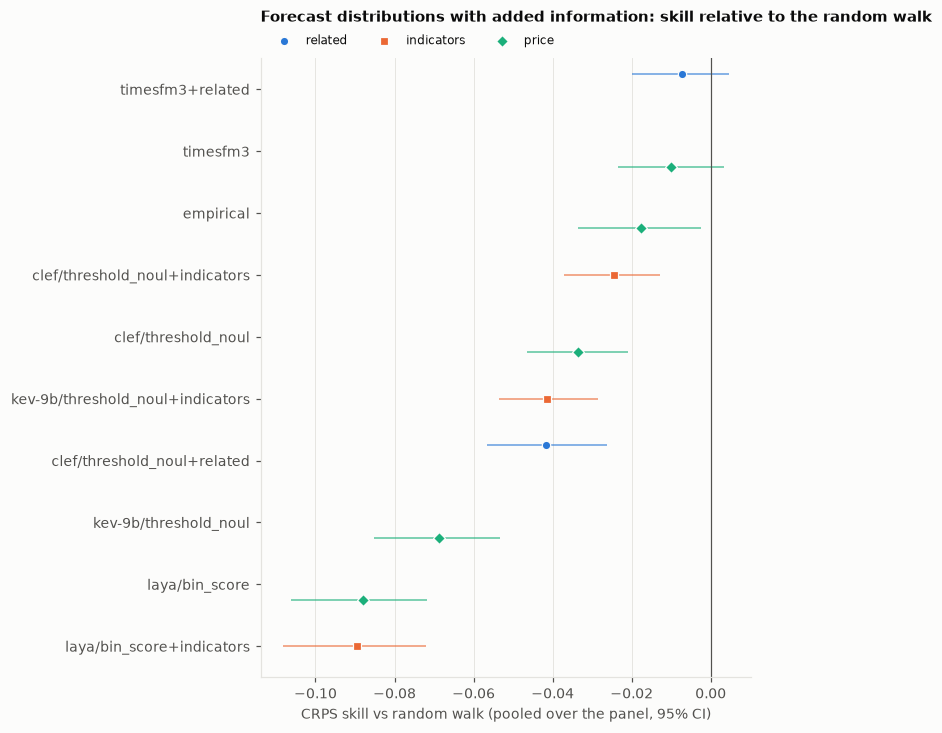

In [9]:
HUE_ORDER = ["related", "indicators", "price"]   # same colour per variant in every chart
sk = skill_table(full, "crps_n").merge(per[["predictor", "variant"]].drop_duplicates(), on="predictor")
plots.dot_plot(sk.sort_values("variant", key=lambda v: v.map(HUE_ORDER.index)), y="predictor", x="skill",
               hue="variant", lo="lo", hi="hi", order=sk.sort_values("skill", ascending=False)["predictor"],
               xlabel="CRPS skill vs random walk (pooled over the panel, 95% CI)",
               title="Forecast distributions with added information: skill relative to the random walk",
               path=CHARTS / "01_crps_skill.png");

### Each variant against the same model on price only

The skill of each variant *relative to the same model's price-only forecasts* (1 − score with the variant / score on price only, paired on decision points). Positive means the added information improved that model's forecasts, whether or not it brought them up to the random walk.

,,skill,lo,hi,N
model,variant,,,,
timesfm3 (CRPS),related,0.003,-0.006,0.011,1228
timesfm3 (Brier on P(up)),related,0.006,-0.007,0.020,1228
clef/threshold_noul (CRPS),related,-0.008,-0.017,0.001,1228
clef/threshold_noul (Brier on P(up)),related,-0.002,-0.016,0.011,1228
lev/direction_choice (Brier on P(up)),related,0.014,-0.002,0.029,1228
clef/threshold_noul (CRPS),indicators,0.009,-0.001,0.019,1228
clef/threshold_noul (Brier on P(up)),indicators,0.007,-0.009,0.022,1228
lev/direction_choice (Brier on P(up)),indicators,0.003,-0.017,0.023,1228
kev-9b/threshold_noul (CRPS),indicators,0.026,0.016,0.036,1228


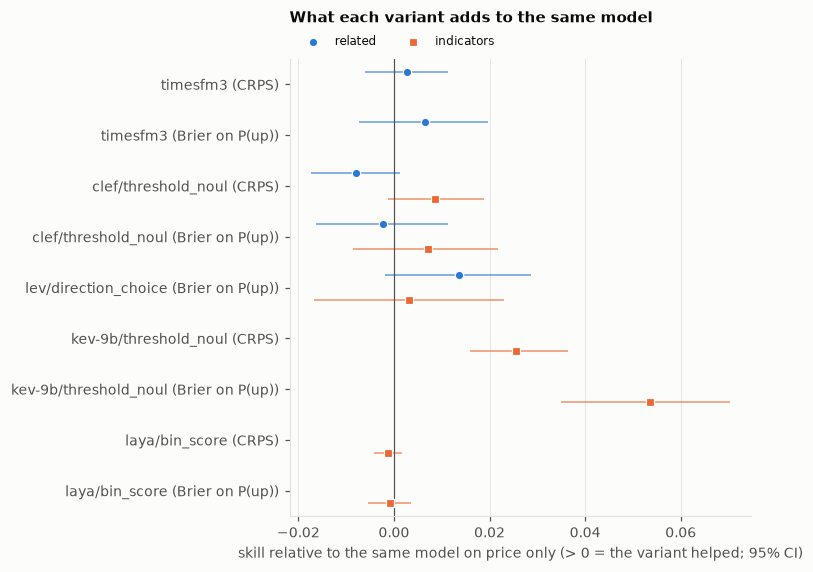

In [10]:
rows = []
for name in per.loc[per["variant"] != "price", "predictor"].unique():
    base, variant = name.split("+")
    for metric, label in METRICS.items():
        d = per[per["predictor"].isin([name, base])].dropna(subset=[metric])
        if d["predictor"].nunique() < 2:
            continue   # direction-only formats have no CRPS
        s = skill_table(d, metric, baseline=base).iloc[0]
        rows.append({"model": f"{base} ({label})", "variant": variant, "skill": s["skill"],
                     "lo": s["lo"], "hi": s["hi"], "N": s["N"]})
gain = pd.DataFrame(rows)
plots.dot_plot(gain, y="model", x="skill", hue="variant", lo="lo", hi="hi",
               xlabel="skill relative to the same model on price only (> 0 = the variant helped; 95% CI)",
               title="What each variant adds to the same model", path=CHARTS / "02_variant_vs_price.png")
gain.set_index(["model", "variant"])

### By asset class

Skill against the random walk on each class's decision points (two instruments each; blue = better than the random walk, red = worse).

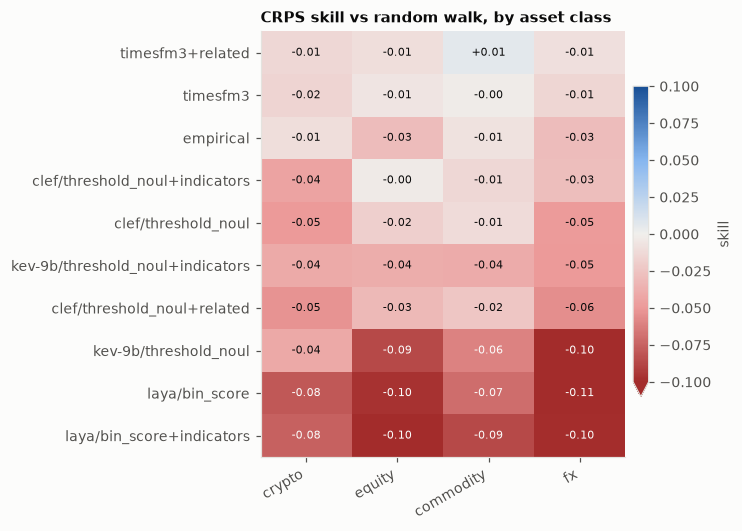

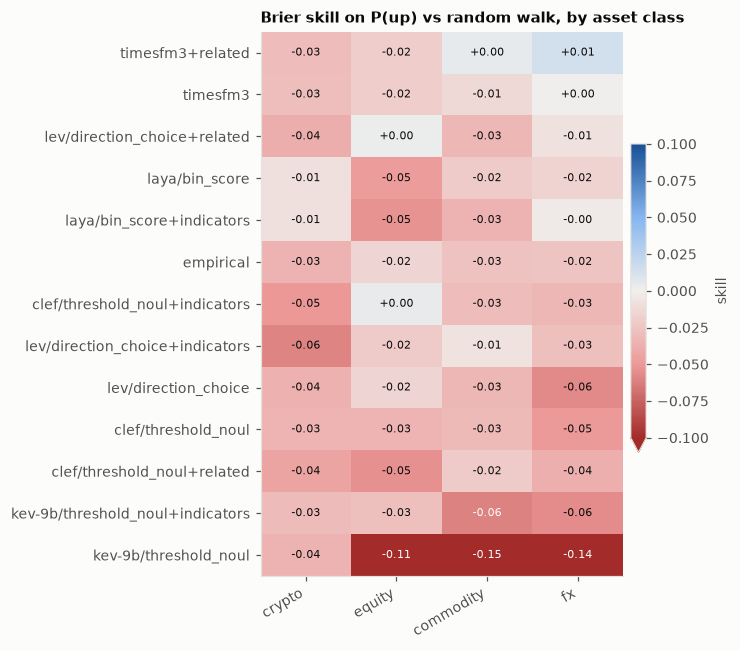

In [11]:
CLASSES = ["crypto", "equity", "commodity", "fx"]


def by_class(df: pd.DataFrame, metric: str) -> pd.DataFrame:
    t = skill_table(df, metric, by=("asset_class",)).pivot(index="predictor", columns="asset_class", values="skill")
    return t[CLASSES].loc[skill_table(df, metric).sort_values("skill", ascending=False)["predictor"]]


plots.heatmap(by_class(full, "crps_n"), span=0.1, title="CRPS skill vs random walk, by asset class",
              cbar_label="skill", path=CHARTS / "03_crps_by_class.png")
plots.heatmap(by_class(per, "brier_up"), span=0.1, title="Brier skill on P(up) vs random walk, by asset class",
              cbar_label="skill", path=CHARTS / "04_brier_by_class.png");

### What the indicators changed in the answers

How each model's P(up) relates to two things the indicator state spells out: Bollinger %B (0 = price on the lower band, 1 = on the upper band) and the move over the previous 20 observations (in units of recent volatility, as in 02). A negative slope means the model expects reversals, a positive one that it expects the move to continue. The realised slopes show what prices actually did at the same decision points.

The Bollinger reversal noted after 02 was found on this same 2024–2026 window, so the realised slope here is not an independent test of it; that test is left to the forward test on new data.

In [12]:
TRAIL = 20
feats = []
for s in SERIES:
    c = s.df["close"]
    mid, sd = c.rolling(20).mean(), c.rolling(20).std()   # as in the indicator state
    lr = np.log(c)
    feats.append(pd.DataFrame({"series": s.key, "t": s.df["t"], "pct_b": (c - (mid - 2 * sd)) / (4 * sd),
                               "trail_z": (lr - lr.shift(TRAIL)) / (lr.diff().rolling(30).std() * np.sqrt(TRAIL))}))
x = per.merge(pd.concat(feats), on=["series", "t"])

points_x = x[x["predictor"] == "random_walk"]
realised = {c: np.polyfit(points_x[c], points_x["up"].astype(float), 1)[0] for c in ("pct_b", "trail_z")}
display(Markdown(f"Realised up-rate slope: {realised['pct_b']:+.3f} per unit of %B, "
                 f"{realised['trail_z']:+.3f} per unit of previous move"))

with_indicators = list(per.loc[per["variant"] == "indicators", "base"].unique())
rows = []
for (base, variant), g in (x[x["base"].isin(with_indicators) & x["variant"].isin(["price", "indicators"])]
                           .dropna(subset=["p_up"]).groupby(["base", "variant"])):
    rows.append({"model": base, "variant": variant, "mean P(up)": g["p_up"].mean(), "sd P(up)": g["p_up"].std(),
                 "slope on %B": np.polyfit(g["pct_b"], g["p_up"], 1)[0],
                 "slope on previous move": np.polyfit(g["trail_z"], g["p_up"], 1)[0]})
pd.DataFrame(rows).set_index(["model", "variant"]).reindex(
    pd.MultiIndex.from_product([with_indicators, ["price", "indicators"]], names=["model", "variant"]))

Realised up-rate slope: -0.064 per unit of %B, -0.002 per unit of previous move

mean P(up)  sd P(up)  slope on %B  slope on previous move
model                 variant                                                              
clef/threshold_noul   price            0.497     0.085       -0.071                  -0.012
                      indicators       0.475     0.081       -0.053                  -0.006
lev/direction_choice  price            0.535     0.112        0.068                   0.033
                      indicators       0.568     0.103        0.130                   0.063
kev-9b/threshold_noul price            0.420     0.090       -0.135                  -0.023
                      indicators       0.466     0.085       -0.077                   0.001
laya/bin_score        price            0.464     0.039       -0.038                  -0.012
                      indicators       0.467     0.043       -0.049                  -0.014

### Interim conclusions: variants A and B

**Neither related assets nor indicators produce skill against the random walk.** TimesFM with related series is the best predictor (CRPS skill −0.007, interval −0.020 to +0.005) and TimesFM on price only is next (−0.010, −0.024 to +0.003); both are statistically tied with the random walk and well calibrated, as in 02. Every decision-model forecast in every variant remains worse than the random walk. Prices rose at 56.1% of decision points.

**1. Related assets (A) add nothing measurable at this horizon.** Against its own price-only forecasts, TimesFM with related covariates gains +0.003 in CRPS (−0.006 to +0.011) and +0.006 in Brier on P(up) (−0.007 to +0.020). For clef the longer state is slightly worse (CRPS −0.008, −0.017 to +0.001); lev's direction answers improve slightly (+0.014, −0.002 to +0.029), an interval that only just reaches zero. Daily closes of other assets, taken as known at the decision time, carry little that the asset's own history does not.

**2. Indicators (B) help the weakest reader, as expected, but do not create skill.** kev-9b gains the most of any model in any variant: +0.026 in CRPS (+0.016 to +0.036) and +0.054 in Brier on P(up) (+0.035 to +0.070), moving its CRPS skill from −0.069 to −0.041, close to clef on price only. The change is in its leanings rather than any new signal: its bearish tilt shrinks (mean P(up) 0.42 to 0.47) and its fading of high %B roughly halves (slope −0.135 to −0.077). clef improves slightly (CRPS +0.009, −0.001 to +0.019), mostly on equities. laya is unaffected (CRPS −0.001, −0.004 to +0.002): its answers hardly move with the state (standard deviation of P(up) about 0.04), so it does not read either version closely enough for the difference to matter. lev's direction answers do not improve (+0.003, −0.017 to +0.023), and with indicators it follows the move more strongly (slope on %B +0.068 to +0.130), against what prices did at these decision points.

**3. Precomputed indicators make decision models less biased, not better informed.** This matches the expectation set before the run: indicators are functions of the prices, so they can correct how a model reads the series but cannot add information the series lacks. They are worth keeping in the state for weaker models; the Bollinger reversal remains a hypothesis for the forward test.

Variants C (news) and D (search interest) bring information that is not in the prices; they follow below.